In [2]:
import os
import urllib.request

CSV_YOLU = "data/penguins.csv"
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"

if not os.path.exists(CSV_YOLU):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, CSV_YOLU)
    print("Veri seti indirildi.")
else:
    print("Veri seti mevcut:", CSV_YOLU)

Veri seti mevcut: data/penguins.csv


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline

df = pd.read_csv(CSV_YOLU)
print("Veri seti başarıyla yüklendi.")
df.head(10)

Veri seti başarıyla yüklendi.


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.10,18.70,181.00,3750.00,MALE
1,Adelie,Torgersen,39.50,17.40,186.00,3800.00,FEMALE
2,Adelie,Torgersen,40.30,18.00,195.00,3250.00,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.70,19.30,193.00,3450.00,FEMALE
5,Adelie,Torgersen,39.30,20.60,190.00,3650.00,MALE
6,Adelie,Torgersen,38.90,17.80,181.00,3625.00,FEMALE
7,Adelie,Torgersen,39.20,19.60,195.00,4675.00,MALE
8,Adelie,Torgersen,34.10,18.10,193.00,3475.00,NaN
9,Adelie,Torgersen,42.00,20.20,190.00,4250.00,NaN


In [4]:
df.tail()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.80,14.30,215.00,4850.00,FEMALE
341,Gentoo,Biscoe,50.40,15.70,222.00,5750.00,MALE
342,Gentoo,Biscoe,45.20,14.80,212.00,5200.00,FEMALE
343,Gentoo,Biscoe,49.90,16.10,213.00,5400.00,MALE


In [5]:
print(f"Gözlem (satır) sayısı : {df.shape[0]}")
print(f"Değişken (sütun) sayısı: {df.shape[1]}")
print()
df.info()

Gözlem (satır) sayısı : 344
Değişken (sütun) sayısı: 7

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [6]:
sayisal = df.select_dtypes(include="number").columns.tolist()
kategorik = df.select_dtypes(exclude="number").columns.tolist()
print("Sayısal değişkenler  :", sayisal)
print("Kategorik değişkenler:", kategorik)

Sayısal değişkenler  : ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
Kategorik değişkenler: ['species', 'island', 'sex']


In [7]:
eksik = pd.DataFrame({
    "Eksik Sayısı": df.isna().sum(),
    "Eksik Oranı (%)": (df.isna().mean() * 100).round(2),
})
eksik

,Eksik Sayısı,Eksik Oranı (%)
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20


In [8]:
df[df[sayisal].isna().all(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


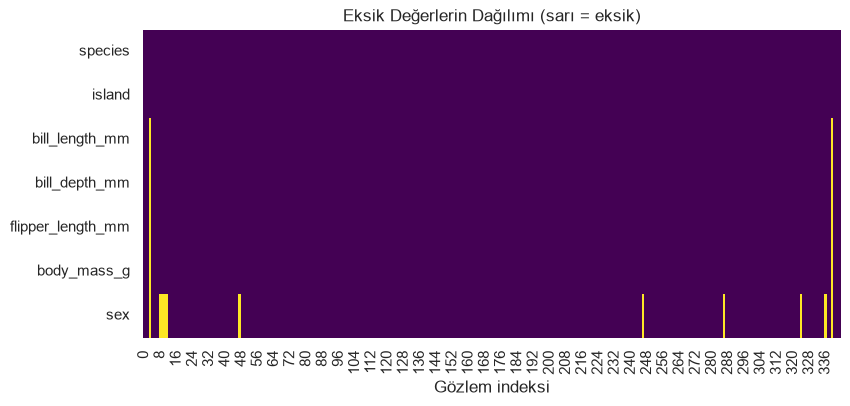

In [8]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isna().T, cbar=False, cmap="viridis")
plt.title("Eksik Değerlerin Dağılımı (sarı = eksik)")
plt.xlabel("Gözlem indeksi")
plt.show()

In [9]:
print("Tekrarlanan satır sayısı:", df.duplicated().sum())
print()
df.nunique().to_frame("Benzersiz Değer Sayısı")

Tekrarlanan satır sayısı: 0



,Benzersiz Değer Sayısı
species,3
island,3
bill_length_mm,164
bill_depth_mm,80
flipper_length_mm,55
body_mass_g,94
sex,2


In [10]:
for kol in kategorik:
    tablo = pd.DataFrame({
        "Frekans": df[kol].value_counts(dropna=False),
        "Oran (%)": (df[kol].value_counts(dropna=False, normalize=True) * 100).round(2),
    })
    print(f"--- {kol} ---")
    display(tablo)

--- species ---


,Frekans,Oran (%)
species,,
Adelie,152,44.19
Gentoo,124,36.05
Chinstrap,68,19.77


--- island ---


,Frekans,Oran (%)
island,,
Biscoe,168,48.84
Dream,124,36.05
Torgersen,52,15.12


--- sex ---


,Frekans,Oran (%)
sex,,
MALE,168,48.84
FEMALE,165,47.97
NaN,11,3.20


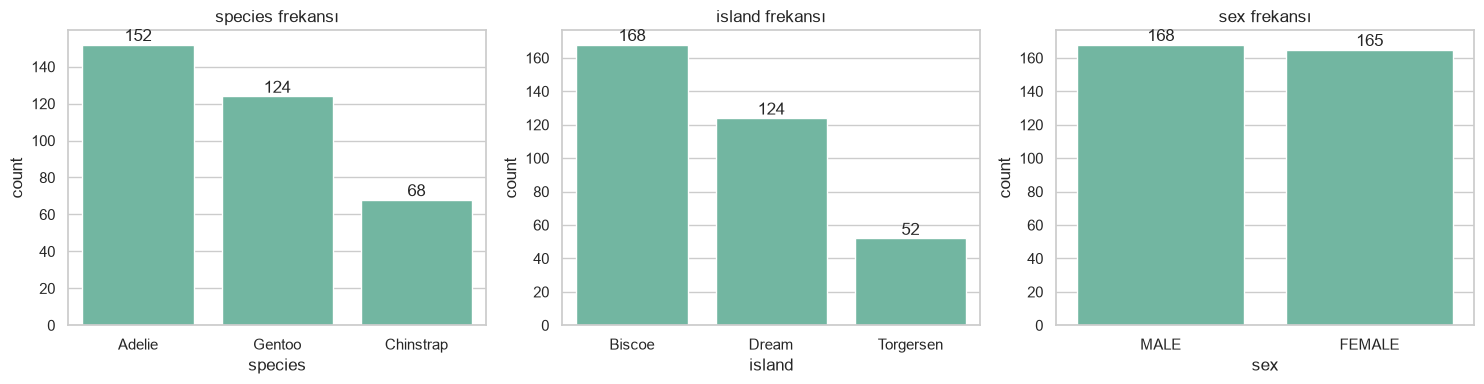

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kol in zip(axes, kategorik):
    sns.countplot(data=df, x=kol, ax=ax, order=df[kol].value_counts().index)
    ax.set_title(f"{kol} frekansı")
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom")
plt.tight_layout()
plt.show()

In [12]:
pd.crosstab(df["species"], df["island"], margins=True, margins_name="Toplam")

island,Biscoe,Dream,Torgersen,Toplam
species,,,,
Adelie,44,56,52,152
Chinstrap,0,68,0,68
Gentoo,124,0,0,124
Toplam,168,124,52,344


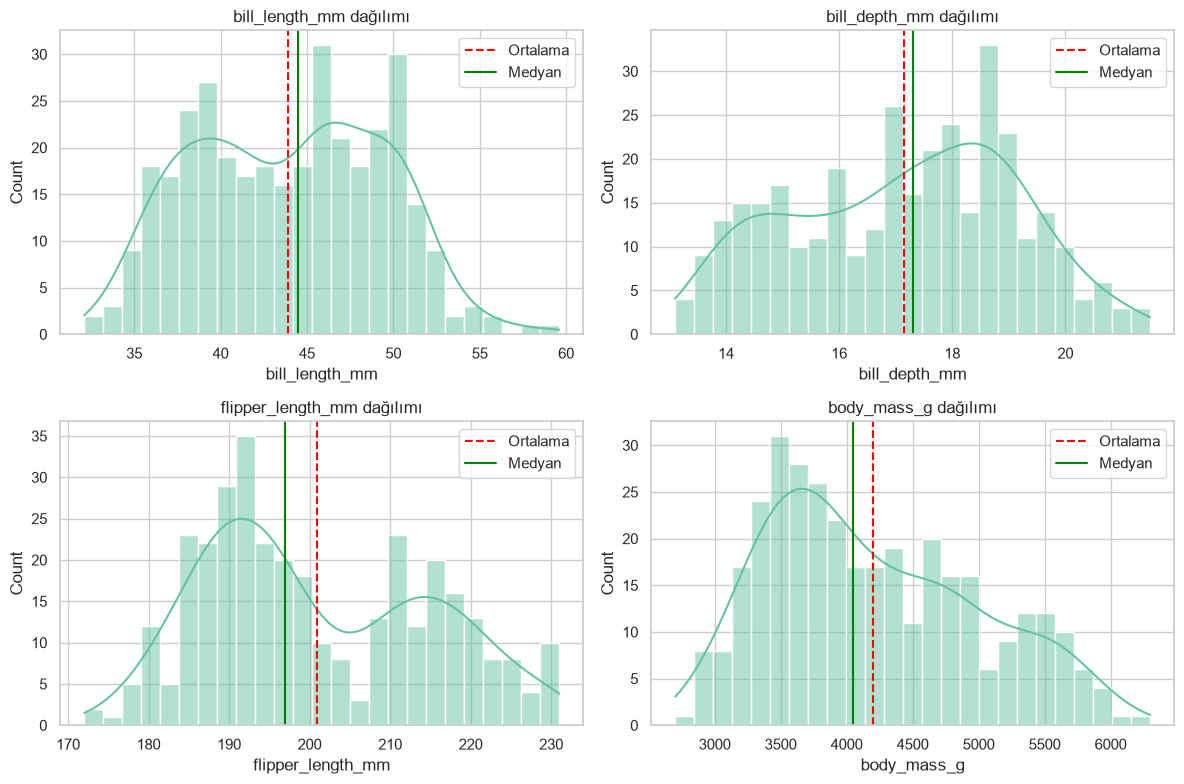

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, kol in zip(axes.flat, sayisal):
    sns.histplot(df[kol], kde=True, ax=ax, bins=25)
    ax.axvline(df[kol].mean(), color="red", linestyle="--", label="Ortalama")
    ax.axvline(df[kol].median(), color="green", linestyle="-", label="Medyan")
    ax.set_title(f"{kol} dağılımı")
    ax.legend()
plt.tight_layout()
plt.show()

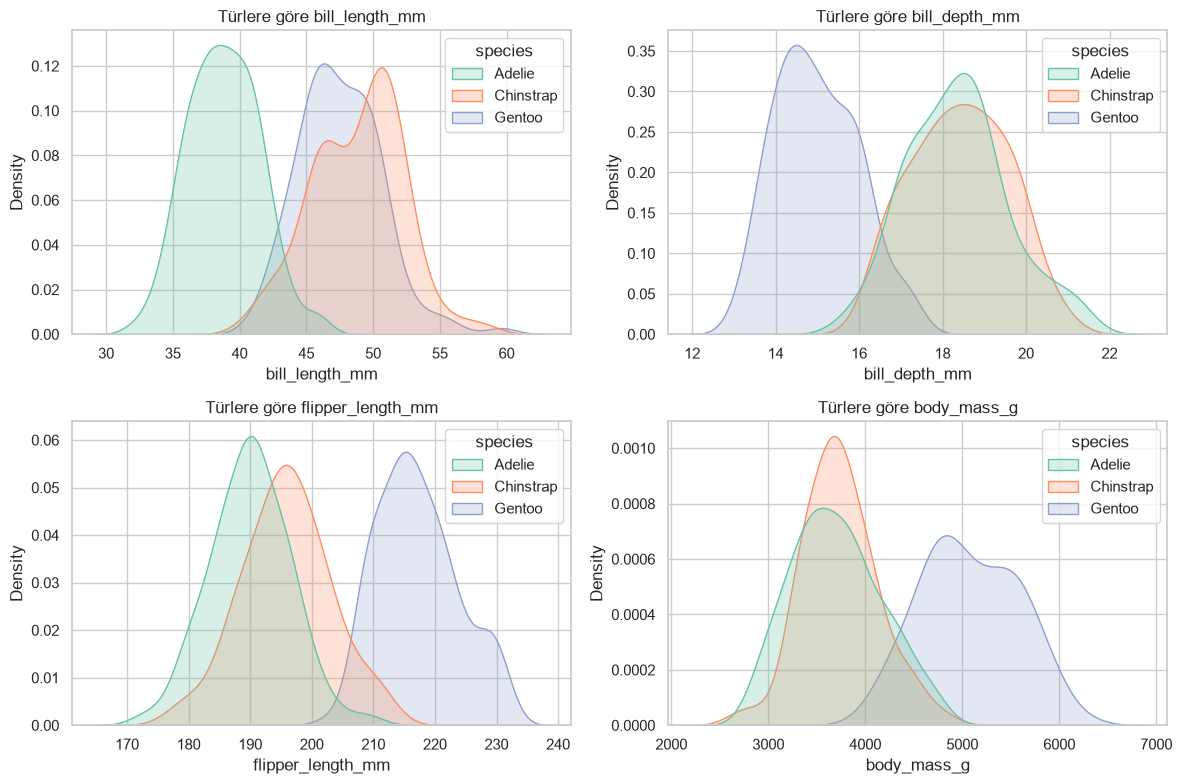

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, kol in zip(axes.flat, sayisal):
    sns.kdeplot(data=df, x=kol, hue="species", fill=True, ax=ax, common_norm=False)
    ax.set_title(f"Türlere göre {kol}")
plt.tight_layout()
plt.show()

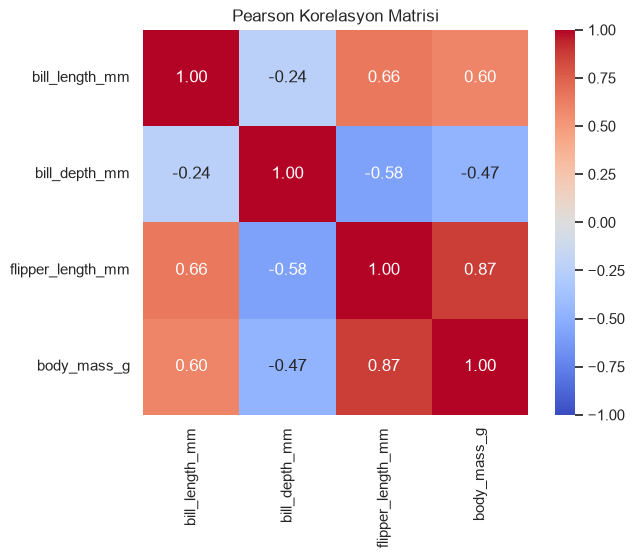

In [15]:
korelasyon = df[sayisal].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(korelasyon, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Pearson Korelasyon Matrisi")
plt.show()

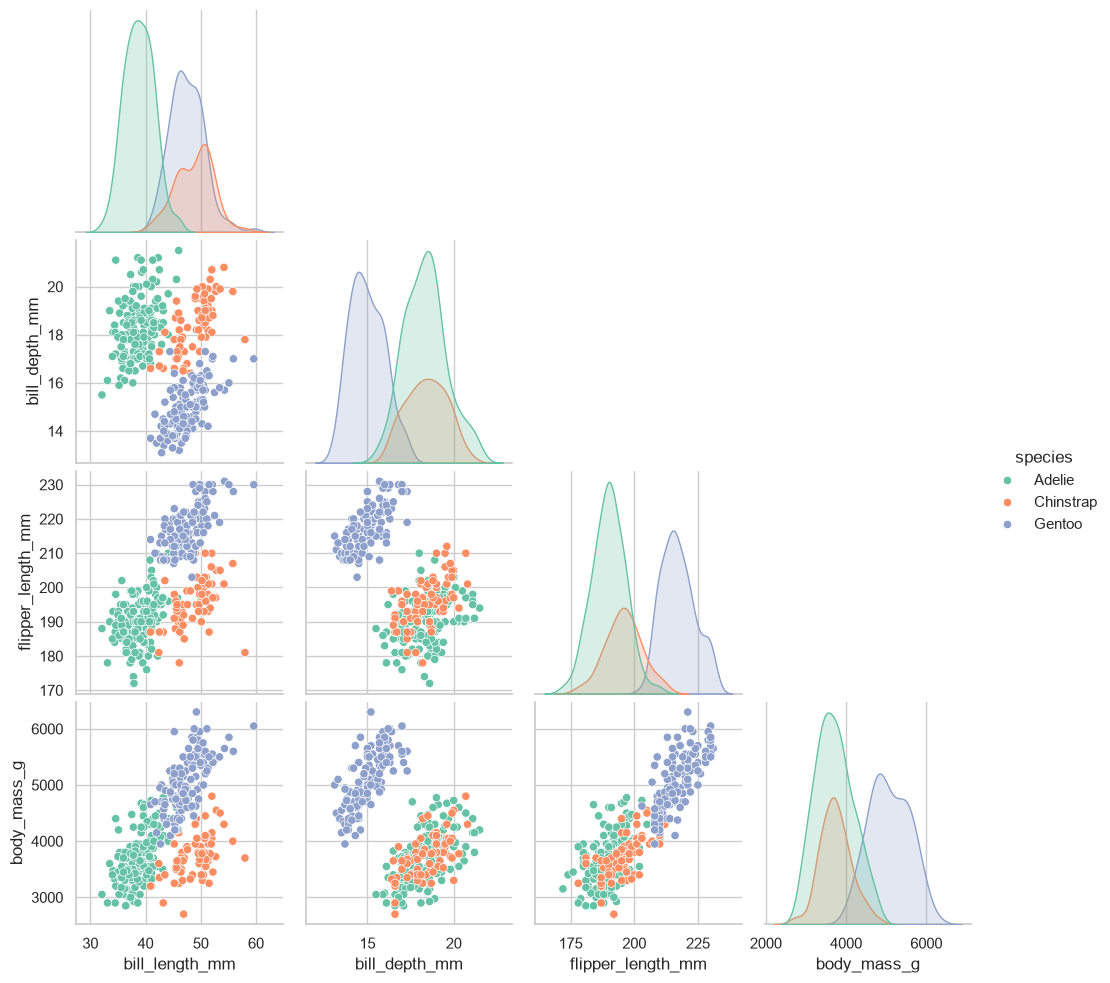

In [16]:
sns.pairplot(df, hue="species", corner=True, diag_kind="kde")
plt.show()

In [17]:
print("Tüm veri korelasyonu:", round(df["bill_length_mm"].corr(df["bill_depth_mm"]), 2))
df.groupby("species")[["bill_length_mm", "bill_depth_mm"]].corr().iloc[0::2, -1].rename("tür içi korelasyon")

Tüm veri korelasyonu: -0.24


species                  
Adelie     bill_length_mm   0.39
Chinstrap  bill_length_mm   0.65
Gentoo     bill_length_mm   0.64
Name: tür içi korelasyon, dtype: float64

In [18]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.00,43.92,5.46,32.10,39.23,44.45,48.50,59.60
bill_depth_mm,342.00,17.15,1.97,13.10,15.60,17.30,18.70,21.50
flipper_length_mm,342.00,200.92,14.06,172.00,190.00,197.00,213.00,231.00
body_mass_g,342.00,4201.75,801.95,2700.00,3550.00,4050.00,4750.00,6300.00


In [19]:
df.describe(exclude="number").T

,count,unique,top,freq
species,344,3,Adelie,152
island,344,3,Biscoe,168
sex,333,2,MALE,168


In [20]:
def aciklayici_tablo(veri):
    satirlar = {}
    for kol in veri.select_dtypes(include="number").columns:
        s = veri[kol].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        alt, ust = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        satirlar[kol] = {
            "Gözlem (n)": s.count(),
            "Eksik": veri[kol].isna().sum(),
            "Ortalama": s.mean(),
            "Medyan": s.median(),
            "Mod": s.mode().iloc[0],
            "Std. Sapma": s.std(),
            "Varyans": s.var(),
            "Std. Hata": stats.sem(s),
            "Değişim Katsayısı (%)": s.std() / s.mean() * 100,
            "Minimum": s.min(),
            "Q1 (%25)": q1,
            "Q3 (%75)": q3,
            "Maksimum": s.max(),
            "Açıklık (Range)": s.max() - s.min(),
            "IQR": iqr,
            "Çarpıklık (Skewness)": s.skew(),
            "Basıklık (Kurtosis)": s.kurt(),
            "Aykırı Değer (IQR)": int(((s < alt) | (s > ust)).sum()),
            "%95 GA Alt": stats.t.interval(0.95, len(s) - 1, loc=s.mean(), scale=stats.sem(s))[0],
            "%95 GA Üst": stats.t.interval(0.95, len(s) - 1, loc=s.mean(), scale=stats.sem(s))[1],
        }
    return pd.DataFrame(satirlar)

ozet_tablo = aciklayici_tablo(df)
ozet_tablo

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
Gözlem (n),342.00,342.00,342.00,342.00
Eksik,2.00,2.00,2.00,2.00
Ortalama,43.92,17.15,200.92,4201.75
Medyan,44.45,17.30,197.00,4050.00
Mod,41.10,17.00,190.00,3800.00
Std. Sapma,5.46,1.97,14.06,801.95
Varyans,29.81,3.90,197.73,643131.08
Std. Hata,0.30,0.11,0.76,43.36
Değişim Katsayısı (%),12.43,11.51,7.00,19.09
Minimum,32.10,13.10,172.00,2700.00


In [21]:
normallik = []
for kol in sayisal:
    s = df[kol].dropna()
    istatistik, p = stats.shapiro(s)
    normallik.append({"Değişken": kol, "W": istatistik, "p-değeri": p,
                      "Normal mi? (α=0.05)": "Evet" if p > 0.05 else "Hayır"})
pd.DataFrame(normallik).set_index("Değişken")

,W,p-değeri,Normal mi? (α=0.05)
Değişken,,,
bill_length_mm,0.97,0.00,Hayır
bill_depth_mm,0.97,0.00,Hayır
flipper_length_mm,0.95,0.00,Hayır
body_mass_g,0.96,0.00,Hayır


In [22]:
df.groupby("species")[sayisal].agg(["mean", "median", "std", "min", "max"]).T

species                   Adelie  Chinstrap  Gentoo
bill_length_mm    mean     38.79      48.83   47.50
                  median   38.80      49.55   47.30
                  std       2.66       3.34    3.08
                  min      32.10      40.90   40.90
                  max      46.00      58.00   59.60
bill_depth_mm     mean     18.35      18.42   14.98
                  median   18.40      18.45   15.00
                  std       1.22       1.14    0.98
                  min      15.50      16.40   13.10
                  max      21.50      20.80   17.30
flipper_length_mm mean    189.95     195.82  217.19
                  median  190.00     196.00  216.00
                  std       6.54       7.13    6.48
                  min     172.00     178.00  203.00
                  max     210.00     212.00  231.00
body_mass_g       mean   3700.66    3733.09 5076.02
                  median 3700.00    3700.00 5000.00
                  std     458.57     384.34  504.12
                  min    2850.00    2700.00 3950.00
                  max    4775.00    4800.00 6300.00

In [23]:
df.groupby(["species", "sex"])[sayisal].mean()

bill_length_mm  bill_depth_mm  flipper_length_mm  \
species   sex                                                        
Adelie    FEMALE           37.26          17.62             187.79   
          MALE             40.39          19.07             192.41   
Chinstrap FEMALE           46.57          17.59             191.74   
          MALE             51.09          19.25             199.91   
Gentoo    FEMALE           45.56          14.24             212.71   
          MALE             49.47          15.72             221.54   

                  body_mass_g  
species   sex                  
Adelie    FEMALE      3368.84  
          MALE        4043.49  
Chinstrap FEMALE      3527.21  
          MALE        3938.97  
Gentoo    FEMALE      4679.74  
          MALE        5484.84

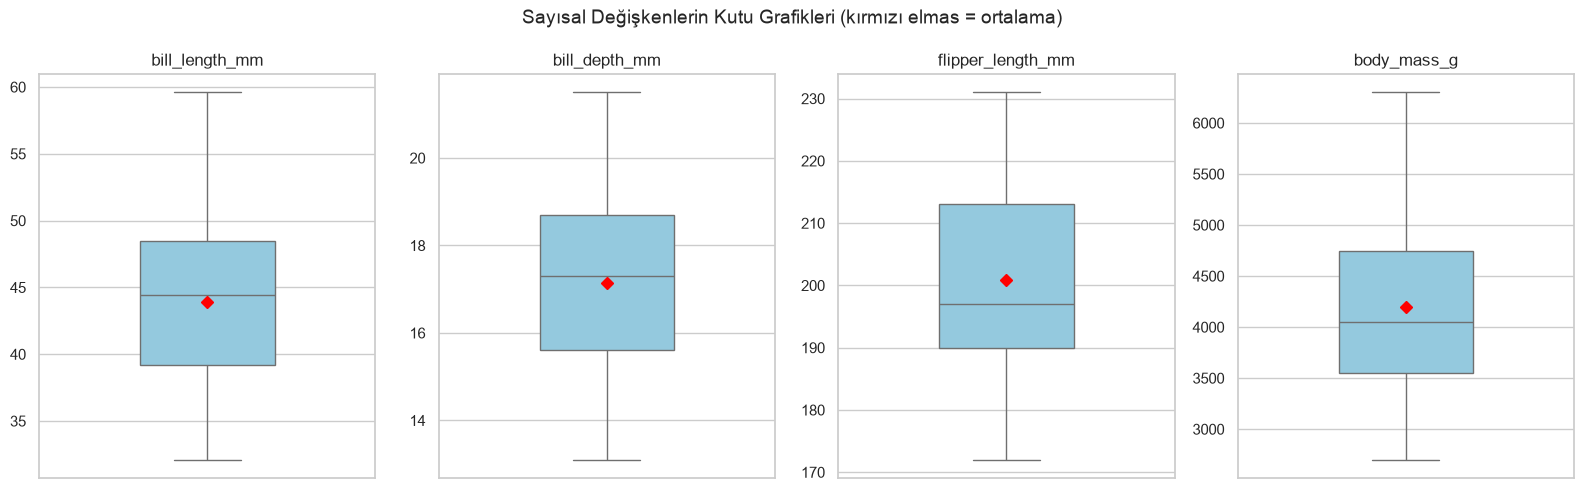

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, kol in zip(axes, sayisal):
    sns.boxplot(y=df[kol], ax=ax, width=0.4, color="skyblue",
                showmeans=True, meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "red"})
    ax.set_title(kol)
    ax.set_ylabel("")
fig.suptitle("Sayısal Değişkenlerin Kutu Grafikleri (kırmızı elmas = ortalama)", fontsize=14)
plt.tight_layout()
plt.show()

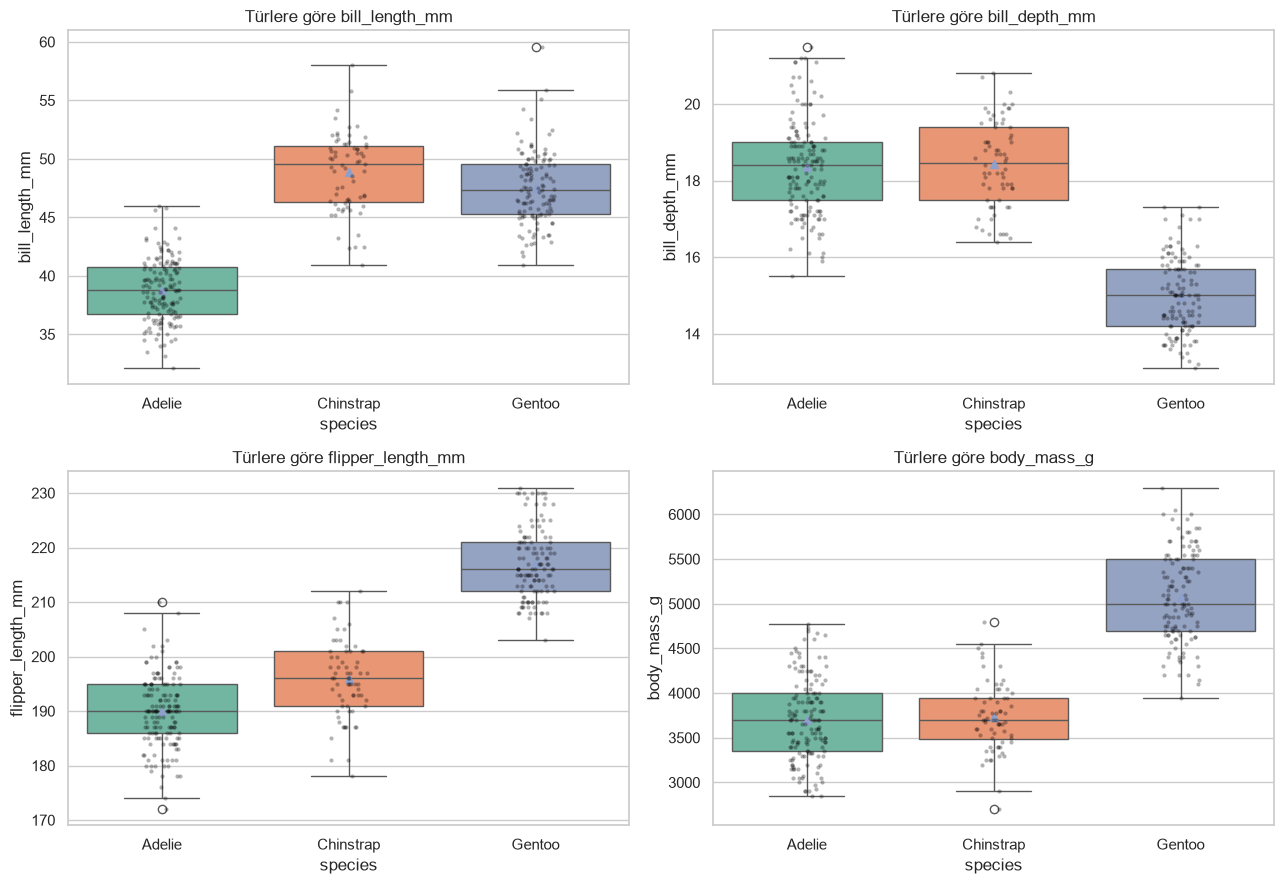

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, kol in zip(axes.flat, sayisal):
    sns.boxplot(data=df, x="species", y=kol, hue="species", ax=ax, showmeans=True, legend=False)
    sns.stripplot(data=df, x="species", y=kol, ax=ax, color="black", alpha=0.3, size=3)
    ax.set_title(f"Türlere göre {kol}")
plt.tight_layout()
plt.show()

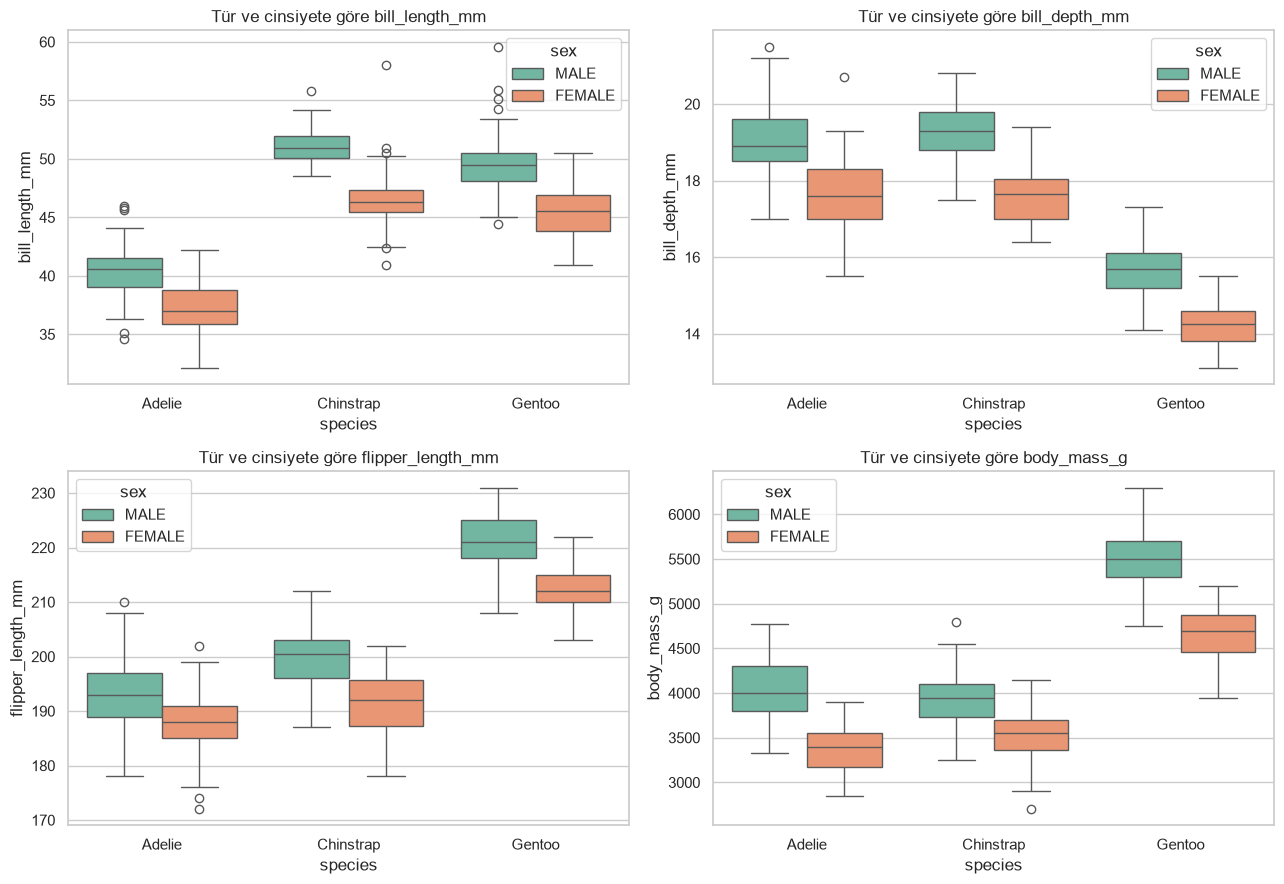

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, kol in zip(axes.flat, sayisal):
    sns.boxplot(data=df, x="species", y=kol, hue="sex", ax=ax)
    ax.set_title(f"Tür ve cinsiyete göre {kol}")
plt.tight_layout()
plt.show()

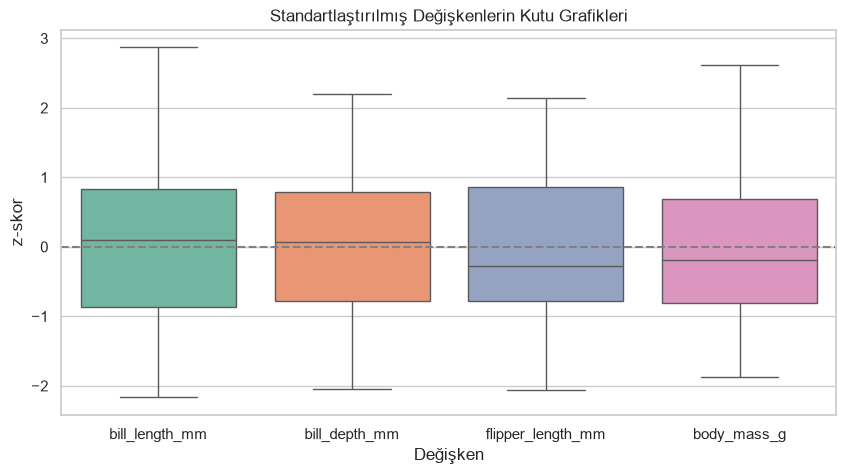

In [27]:
z = (df[sayisal] - df[sayisal].mean()) / df[sayisal].std()
plt.figure(figsize=(10, 5))
sns.boxplot(data=z.melt(var_name="Değişken", value_name="z-skor"), x="Değişken", y="z-skor",
            hue="Değişken", legend=False)
plt.axhline(0, color="gray", linestyle="--")
plt.title("Standartlaştırılmış Değişkenlerin Kutu Grafikleri")
plt.show()